# Índice de busca dos comentários

Transforma cada comentário em um vetor e monta o índice FAISS que a busca por sentido usa para recuperar as evidências das respostas. Um vetor é uma lista de números que representa o significado do texto: comentários com sentido parecido ficam com vetores próximos, mesmo quando usam palavras diferentes.

| Passo | O que é | Decisões |
|---|---|---|
| 1 | documentos: o que vira vetor e o que vai junto como informação anexa | D-028 |
| 2 | modelo de embedding e teste com três comentários | D-007, D-028 |
| 3 | vetores da base inteira | D-028 |
| 4 | índice FAISS | D-028 |
| 5 | função de busca: filtros e diversificação | D-028 |
| 6 | teste da busca com as etiquetas | D-028 |
| 7 | busca nas perguntas do enunciado | D-028 |

📌 Entradas: `data/processed/avaliacoes_enriquecidas.parquet` e `data/processed/etiquetas_base.parquet`.

📌 Saídas: `data/processed/indice_busca/` (fora do repositório), `reports/busca/teste_busca.csv`, `images/busca/acerto_variedade_busca.png` e `images/busca/teste_busca.png`.

## 1. Documentos

Cada comentário é um documento. Os comentários da Olist são curtos, então não há divisão em pedaços (o *chunking* usado para textos longos): cortar um comentário de poucas frases separaria a queixa do seu motivo.

| Parte | O que entra | Para quê |
|---|---|---|
| texto do vetor | título (quando existe) e comentário | a busca por sentido compara a pergunta com o que o cliente escreveu |
| informações anexas (metadados) | código da avaliação, nota, mês, estado, região, faixa de atraso, categorias e etiquetas | filtrar a busca e mostrar a evidência com contexto |

As etiquetas ficam fora do texto do vetor. Se entrassem, a busca passaria a refletir a etiquetagem do modelo, e não as palavras do cliente.

O modelo de embedding pede um formato fixo para o texto dos documentos: `title: {título} | text: {comentário}`, com `title: none` quando a avaliação não tem título.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*langchain-community.*")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
base = pd.read_parquet(RAIZ / "data" / "processed" / "avaliacoes_enriquecidas.parquet")
etiquetas = pd.read_parquet(RAIZ / "data" / "processed" / "etiquetas_base.parquet")

etiquetas_por_comentario = (etiquetas.query("sem_etiqueta == 0")
                            .assign(etiqueta=lambda d: d["sentido"] + " · " + d["tema"] + " · " + d["detalhe"])
                            .groupby("review_id")["etiqueta"].agg(list))

documentos = base[["review_id", "nota", "titulo", "texto", "mes_avaliacao", "estado_cliente", "regiao_cliente",
                   "faixa_atraso", "categorias"]].copy()
documentos["categorias"] = documentos["categorias"].apply(lambda v: list(v) if isinstance(v, (list, np.ndarray)) else [])
documentos["etiquetas"] = documentos["review_id"].map(etiquetas_por_comentario).apply(lambda v: v if isinstance(v, list) else [])
tem_titulo = documentos["titulo"].fillna("").str.strip() != ""
documentos["texto_vetor"] = [
    f"title: {titulo.strip() if com_titulo else 'none'} | text: {texto}"
    for titulo, texto, com_titulo in zip(documentos["titulo"].fillna(""), documentos["texto"], tem_titulo)
]

tamanho = documentos["texto"].str.len()
display(pd.Series(dtype=object, data={
    "documentos (um por comentário)": len(documentos),
    "com título": f"{tem_titulo.sum():,} ({tem_titulo.mean():.0%})".replace(",", "."),
    "caracteres do comentário: mediana": int(tamanho.median()),
    "caracteres do comentário: máximo": int(tamanho.max()),
    "sem etiqueta": int((documentos["etiquetas"].str.len() == 0).sum()),
}).to_frame("valor"))
display(documentos.loc[[0, 1, 2], ["texto_vetor", "nota", "mes_avaliacao", "faixa_atraso", "etiquetas"]])

,valor
documentos (um por comentário),40518
com título,9.755 (24%)
caracteres do comentário: mediana,53
caracteres do comentário: máximo,208
sem etiqueta,1027


,texto_vetor,nota,mes_avaliacao,faixa_atraso,etiquetas
0,title: Entrega rápida! | text: A entrega foi s...,5,2018-04,dentro do prazo,"[positivo · entrega · prazo, positivo · produt..."
1,title: SUPER RECOMENDO | text: GOSTEI DA CAPIN...,5,2018-07,dentro do prazo,[positivo · produto · conformidade com o anúncio]
2,title: none | text: otimo produto. prazo cumpr...,5,2017-09,dentro do prazo,"[positivo · produto · qualidade, positivo · en..."


**Leitura.** São 40.518 documentos, um por comentário. O comentário mediano tem 53 caracteres e o maior, 208, o que confirma que não há o que dividir. O título aparece em 24% das avaliações e entra no texto do vetor. Os 1.027 comentários sem etiqueta continuam no índice: não aparecem nas contagens, mas podem ser encontrados pela busca.

## 2. Modelo de embedding

O modelo é o `gemini-embedding-2`, o mais recente do Google, chamado pelo LangChain como na aula 3 (D-007). Cada texto vira um vetor de 768 números (D-028). O modelo aceita vetores de até 3.072 números; com 768, o índice ocupa um quarto do espaço, com perda pequena de qualidade segundo a documentação do Google.

A pergunta e o documento recebem formatos diferentes, porque são textos de natureza diferente: a pergunta é curta e procura algo, o documento é o conteúdo a ser encontrado. O modelo foi treinado para aproximar os dois quando o documento responde à pergunta.

| Texto | Formato enviado ao modelo |
|---|---|
| documento | `title: {título} \| text: {comentário}` |
| pergunta | `task: search result \| query: {pergunta}` |

A classe `EmbeddingDeBusca` aplica o formato da pergunta automaticamente, para que nenhuma busca o esqueça. O teste abaixo envia três comentários e uma pergunta: se o modelo funciona como esperado, o comentário que responde à pergunta tem a maior similaridade. A similaridade vai de -1 a 1; quanto mais perto de 1, mais parecido o sentido.

In [2]:
from dotenv import load_dotenv
from langchain_core.embeddings import Embeddings
from langchain_google_genai import GoogleGenerativeAIEmbeddings

load_dotenv(RAIZ / ".env", override=True)
MODELO_EMBEDDING = "gemini-embedding-2"
DIMENSOES = 768
PRECO_EMBEDDING = 0.20  # US$ por 1 milhão de tokens de entrada


class EmbeddingDeBusca(Embeddings):
    """Embedding do Google com o formato de pergunta do gemini-embedding-2."""

    def __init__(self):
        self.modelo = GoogleGenerativeAIEmbeddings(model=MODELO_EMBEDDING, output_dimensionality=DIMENSOES)

    def embed_documents(self, textos):
        # os documentos já chegam no formato "title: ... | text: ..."
        return self.modelo.embed_documents(textos)

    def embed_query(self, pergunta):
        return self.modelo.embed_query(f"task: search result | query: {pergunta}")


embedding = EmbeddingDeBusca()

comentarios_teste = [
    "title: none | text: Até hoje não recebi o produto, já passou do prazo",
    "title: none | text: Chegou rápido e muito bem embalado",
    "title: none | text: A peça veio quebrada dentro da caixa",
]
pergunta_teste = "produto não foi entregue"
vetores_teste = np.array(embedding.embed_documents(comentarios_teste))
vetor_pergunta = np.array(embedding.embed_query(pergunta_teste))

print(f"pergunta: {pergunta_teste}")
print(f"tamanho de cada vetor: {vetores_teste.shape[1]} números | tamanho (norma) dos vetores: {np.linalg.norm(vetores_teste, axis=1).round(3)}")
display(pd.DataFrame({"comentário": comentarios_teste, "similaridade com a pergunta": (vetores_teste @ vetor_pergunta).round(3)})
        .sort_values("similaridade com a pergunta", ascending=False))

pergunta: produto não foi entregue
tamanho de cada vetor: 768 números | tamanho (norma) dos vetores: [1. 1. 1.]


,comentário,similaridade com a pergunta
0,title: none | text: Até hoje não recebi o prod...,0.853
2,title: none | text: A peça veio quebrada dentr...,0.734
1,title: none | text: Chegou rápido e muito bem ...,0.713


**Leitura.** O comentário que responde à pergunta ficou em primeiro, com similaridade de 0,85, contra 0,73 e 0,71 dos outros dois. Ele não repete as palavras da pergunta ("não foi entregue" e "não recebi"), o que mostra que a comparação é pelo sentido. Os outros dois não ficam perto de zero porque também falam de compra e entrega; o que importa para a busca é a ordem. Os vetores têm 768 números e tamanho 1, então o produto entre dois vetores já é a similaridade, sem ajuste.

## 3. Vetores da base inteira

Antes de chamar o modelo, os tokens dos 40.518 documentos são contados, o que não tem custo, para confirmar o preço da vetorização. Depois os documentos seguem em lotes de 100, o máximo por chamada, com 4 chamadas simultâneas. O plano pago permite 3.000 textos por minuto para este modelo, o que limita a vetorização a 30 lotes por minuto.

| Elemento | Como é feito |
|---|---|
| retomada | cada lote é gravado em `data/processed/vetores_busca/` assim que volta, e a contagem de tokens também; o que já foi gravado não é reenviado |
| falhas | um lote com erro é repetido até 6 vezes, com espera crescente de até 60 segundos, o tempo de renovação do limite por minuto |
| conferências | um vetor por documento, todos com 768 números e tamanho 1 |

In [3]:
import time
from concurrent.futures import ThreadPoolExecutor, as_completed

TAMANHO_LOTE_VETORES = 100
PARALELO_VETORES = 4  # o plano permite 3.000 textos por minuto para este modelo
PASTA_VETORES = RAIZ / "data" / "processed" / "vetores_busca"
PASTA_VETORES.mkdir(parents=True, exist_ok=True)

textos = documentos["texto_vetor"].tolist()


def contar_tokens():
    """Tokens dos documentos, contados uma vez e gravados com os lotes."""
    arquivo = PASTA_VETORES / "tokens.txt"
    if arquivo.exists():
        return int(arquivo.read_text())
    cliente = embedding.modelo.client
    total = 0
    for i in range(0, len(textos), 2000):
        for tentativa in range(1, 5):
            try:
                total += cliente.models.count_tokens(model=MODELO_EMBEDDING, contents=textos[i:i + 2000]).total_tokens
                break
            except Exception:
                if tentativa == 4:
                    raise
                time.sleep(10 * tentativa)
    arquivo.write_text(str(total))
    return total


tokens = contar_tokens()
print(f"tokens: {tokens:,} | custo previsto: US$ {tokens * PRECO_EMBEDDING / 1e6:.2f}".replace(",", "."))


def vetorizar(numero, inicio):
    arquivo = PASTA_VETORES / f"lote_{numero:04d}.npy"
    if arquivo.exists():
        return numero, np.load(arquivo)
    lote = textos[inicio:inicio + TAMANHO_LOTE_VETORES]
    for tentativa in range(1, 7):
        try:
            vetores_lote = np.asarray(embedding.embed_documents(lote), dtype="float32")
            break
        except Exception:
            if tentativa == 6:
                raise
            time.sleep(min(60, 15 * tentativa))  # espera a janela de um minuto do limite
    assert vetores_lote.shape == (len(lote), DIMENSOES)
    np.save(arquivo, vetores_lote)
    return numero, vetores_lote


inicio_relogio = time.perf_counter()
inicios = list(range(0, len(textos), TAMANHO_LOTE_VETORES))
por_lote = {}
with ThreadPoolExecutor(max_workers=PARALELO_VETORES) as executor:
    futuros = [executor.submit(vetorizar, numero, inicio) for numero, inicio in enumerate(inicios)]
    for feitos, futuro in enumerate(as_completed(futuros), start=1):
        numero, vetores_lote = futuro.result()
        por_lote[numero] = vetores_lote
        if feitos % 100 == 0 or feitos == len(futuros):
            print(f"{feitos} de {len(futuros)} lotes ({time.perf_counter() - inicio_relogio:.0f} s)")

vetores = np.vstack([por_lote[n] for n in range(len(inicios))])
normas = np.linalg.norm(vetores, axis=1)
display(pd.Series(dtype=object, data={
    "documentos vetorizados": len(vetores),
    "números por vetor": vetores.shape[1],
    "tamanho (norma) mínimo e máximo": f"{normas.min():.4f} a {normas.max():.4f}",
    "lotes": len(inicios),
    "tempo desta execução (s)": round(time.perf_counter() - inicio_relogio),
    "tokens": tokens,
    "custo (US$)": round(tokens * PRECO_EMBEDDING / 1e6, 4),
}).to_frame("valor"))

tokens: 919.767 | custo previsto: US$ 0.18
100 de 406 lotes (0 s)


200 de 406 lotes (0 s)


300 de 406 lotes (0 s)
400 de 406 lotes (0 s)
406 de 406 lotes (0 s)


,valor
documentos vetorizados,40518
números por vetor,768
tamanho (norma) mínimo e máximo,1.0000 a 1.0000
lotes,406
tempo desta execução (s),0
tokens,919767
custo (US$),0.184


**Leitura.** Os 40.518 documentos foram vetorizados, todos com 768 números e tamanho 1. Os 919.767 tokens custaram US$ 0,18. A vetorização completa levou cerca de 15 minutos, distribuídos em três execuções: a primeira foi interrompida, e a segunda parou no limite de 3.000 textos por minuto do plano. Como cada lote fica gravado, as retomadas só enviaram os lotes que faltavam, e o tempo da tabela se refere apenas à última execução.

## 4. Índice FAISS

O índice guarda os vetores de forma que a busca encontre rapidamente os mais próximos de uma pergunta. O FAISS oferece índices aproximados, que trocam um pouco de precisão por velocidade em bases de milhões de vetores. Com 40 mil vetores, a busca exata leva milésimos de segundo, então o índice é exato (`IndexFlatIP`): compara a pergunta com todos os comentários.

Como os vetores têm tamanho 1, o produto entre dois vetores é a similaridade do passo 2. O índice é montado pela classe `FAISS` do LangChain, como na aula 3, que guarda junto de cada vetor o texto do comentário e as informações anexas do passo 1.

O índice é gravado em `data/processed/indice_busca/`, com dois arquivos: `index.faiss` (os vetores) e `index.pkl` (textos e informações anexas). Ele fica fora do repositório, porque ultrapassa o limite de 100 MB do GitHub, e é regerado por este notebook (D-028). A conferência abaixo recarrega o índice gravado e faz a busca do passo 2 na base inteira.

In [4]:
import faiss
from langchain_community.docstore.in_memory import InMemoryDocstore
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy
from langchain_core.documents import Document

PASTA_INDICE = RAIZ / "data" / "processed" / "indice_busca"


def limpo(valor):
    return valor if isinstance(valor, str) and valor.strip() else None


indice = faiss.IndexFlatIP(DIMENSOES)
indice.add(vetores)
documentos_indice = {
    str(posicao): Document(page_content=l.texto, metadata={
        "review_id": l.review_id, "nota": int(l.nota), "titulo": limpo(l.titulo), "mes": l.mes_avaliacao,
        "estado": limpo(l.estado_cliente), "regiao": limpo(l.regiao_cliente), "faixa_atraso": limpo(l.faixa_atraso),
        "categorias": l.categorias, "etiquetas": l.etiquetas,
    })
    for posicao, l in enumerate(documentos.itertuples())
}
loja = FAISS(embedding_function=embedding, index=indice, docstore=InMemoryDocstore(documentos_indice),
             index_to_docstore_id={posicao: str(posicao) for posicao in range(len(documentos_indice))},
             distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)
loja.save_local(str(PASTA_INDICE))

# conferência: o índice gravado é recarregado e consultado
# o arquivo index.pkl é gerado por este notebook, por isso a leitura dele é liberada
loja = FAISS.load_local(str(PASTA_INDICE), embedding, allow_dangerous_deserialization=True,
                        distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)
tamanhos = " e ".join(f"{a.name} ({a.stat().st_size / 1e6:.0f} MB)" for a in sorted(PASTA_INDICE.iterdir()))
print(f"vetores no índice: {loja.index.ntotal:,}".replace(",", ".") + f" | arquivos: {tamanhos}")

achados = loja.similarity_search_with_score("produto não foi entregue", k=5)
display(pd.DataFrame([{"similaridade": round(float(s), 3), "nota": d.metadata["nota"], "comentário": d.page_content,
                       "etiquetas": "; ".join(d.metadata["etiquetas"])} for d, s in achados]))

vetores no índice: 40.518 | arquivos: index.faiss (124 MB) e index.pkl (13 MB)


,similaridade,nota,comentário,etiquetas
0,0.928,1,o produto não foi entregue,negativo · entrega · não recebido
1,0.928,1,o produto não foi entregue,negativo · entrega · não recebido
2,0.926,1,o produto nao foi entregue,negativo · entrega · não recebido
3,0.919,1,produto n foi entregue,negativo · entrega · não recebido
4,0.916,1,O produto não foi entregue,negativo · entrega · não recebido


**Leitura.** O índice tem os 40.518 vetores e ocupa 137 MB (124 MB de vetores e 13 MB de textos e informações anexas), acima do limite do GitHub, como previsto. Recarregado do disco, ele respondeu à pergunta do passo 2 com cinco comentários de "não recebido", todos de nota 1, com similaridade acima de 0,91.

Os cinco resultados são praticamente a mesma frase ("o produto não foi entregue"), escrita com pequenas variações. Para mostrar evidências, cinco cópias da mesma queixa valem menos que cinco relatos diferentes. A função de busca do passo 5 trata disso: escolhe comentários próximos da pergunta, mas diferentes entre si.

## 5. Função de busca

A função `buscar` recebe a pergunta, a quantidade de comentários desejada e, opcionalmente, filtros. Ela é a base da ferramenta de busca da etapa 6, em que o modelo de linguagem lê a pergunta do usuário e monta os filtros.

| Etapa | O que acontece |
|---|---|
| filtros | as informações anexas definem quais comentários podem ser devolvidos: etiqueta (sentido, tema, detalhe), nota, período, estado, região, faixa de atraso e categoria |
| busca | o FAISS compara a pergunta só com os comentários permitidos pelos filtros e separa os 500 mais próximos (os candidatos) |
| corte | sem filtro de etiqueta, ficam só os candidatos com similaridade a até 0,05 da do primeiro colocado |
| diversificação | entre os candidatos, escolhe os que estão próximos da pergunta e, ao mesmo tempo, diferentes dos já escolhidos |

**Por que diversificar.** A base tem centenas de comentários quase idênticos sobre os assuntos mais comuns. Sem diversificação, a pergunta "produto não foi entregue" devolve cinco vezes a mesma frase, escrita com pequenas variações. Como evidência, cinco relatos diferentes do mesmo problema dizem mais ao gestor do que cinco cópias.

A diversificação usa a técnica MMR (*maximal marginal relevance*), disponível no LangChain. Cada candidato recebe uma nota que pesa a semelhança com a pergunta e a diferença em relação aos comentários já escolhidos. O peso da semelhança vai de 0 a 1: com 1, só a semelhança conta e voltam as repetições; perto de 0, só a diferença conta. O peso usado é 0,3.

**Por que cortar.** Ao buscar variedade, a diversificação tende a escolher os candidatos mais distantes da pergunta, que são os mais prováveis falsos positivos: comentários de assuntos vizinhos, como "não chegou" numa pergunta sobre atraso. O corte descarta esses candidatos antes da escolha. Sem filtro de etiqueta, ele é necessário; com filtro de etiqueta, todos os candidatos já são do assunto, e o corte só reduziria a variedade.

| Situação | Ajuste |
|---|---|
| com filtro de etiqueta (tema ou detalhe) | 500 candidatos, peso 0,3, sem corte |
| sem filtro de etiqueta | 500 candidatos, peso 0,3, corte de 0,05 |

O teste do passo 6 compara esses ajustes com outras combinações.

Os filtros de sentido, tema e detalhe valem para uma mesma etiqueta: `{"sentido": "negativo", "tema": "entrega"}` traz comentários com uma etiqueta negativa de entrega, e não comentários que têm qualquer etiqueta negativa e qualquer etiqueta de entrega.

In [5]:
from langchain_community.vectorstores.utils import maximal_marginal_relevance

AJUSTES = {
    "com etiqueta": {"candidatos": 500, "peso": 0.3, "corte": None},
    "sem etiqueta": {"candidatos": 500, "peso": 0.3, "corte": 0.05},
    "moderado": {"candidatos": 200, "peso": 0.5, "corte": None},  # usado só na comparação do passo 6
}
PARTES_ETIQUETA = {"sentido": 0, "tema": 1, "detalhe": 2}
COLUNAS_FILTRO = {"nota": "nota", "estado": "estado_cliente", "regiao": "regiao_cliente", "faixa_atraso": "faixa_atraso"}


def como_lista(valor):
    return list(valor) if isinstance(valor, (list, tuple, set)) else [valor]


def comentarios_permitidos(filtros):
    """Posições dos comentários que atendem aos filtros; None quando não há filtro."""
    if not filtros:
        return None
    permitido = pd.Series(True, index=documentos.index)
    partes = {campo: como_lista(valor) for campo, valor in filtros.items() if campo in PARTES_ETIQUETA}
    if partes:
        permitido &= documentos["etiquetas"].apply(lambda etiquetas: any(
            all(e.split(" · ")[PARTES_ETIQUETA[campo]] in valores for campo, valores in partes.items()) for e in etiquetas))
    for campo, valor in filtros.items():
        if campo == "etiqueta":
            permitido &= documentos["etiquetas"].apply(lambda etiquetas: any(e in como_lista(valor) for e in etiquetas))
        elif campo == "categoria":
            permitido &= documentos["categorias"].apply(lambda categorias: any(c in como_lista(valor) for c in categorias))
        elif campo == "periodo":
            inicio, fim = valor
            permitido &= documentos["mes_avaliacao"].between(inicio, fim)
        elif campo in COLUNAS_FILTRO:
            permitido &= documentos[COLUNAS_FILTRO[campo]].isin(como_lista(valor))
        elif campo not in PARTES_ETIQUETA:
            raise ValueError(f"filtro desconhecido: {campo}")
    return np.flatnonzero(permitido.to_numpy())


def ajuste_para(filtros):
    """Sem corte quando um filtro de etiqueta garante o assunto; com corte nos demais casos."""
    return "com etiqueta" if filtros and any(campo in filtros for campo in ("etiqueta", "tema", "detalhe")) else "sem etiqueta"


def buscar(pergunta, k=5, filtros=None, diversificar=True, ajuste=None):
    """Comentários mais próximos da pergunta, dentro dos filtros, opcionalmente diversificados."""
    posicoes = comentarios_permitidos(filtros)
    if posicoes is not None and len(posicoes) == 0:
        return pd.DataFrame()
    escolha = AJUSTES[ajuste or ajuste_para(filtros)]
    vetor = np.asarray(embedding.embed_query(pergunta), dtype="float32")
    parametros = None if posicoes is None else faiss.SearchParameters(sel=faiss.IDSelectorBatch(posicoes.astype("int64")))
    similaridades, ids = loja.index.search(vetor[None, :], escolha["candidatos"] if diversificar else k, params=parametros)
    validos = ids[0] >= 0
    similaridades, ids = similaridades[0][validos], ids[0][validos]
    if diversificar and escolha["corte"] is not None:
        perto_do_melhor = similaridades >= similaridades[0] - escolha["corte"]
        similaridades, ids = similaridades[perto_do_melhor], ids[perto_do_melhor]
    if diversificar and len(ids) > k:
        escolhidos = maximal_marginal_relevance(vetor, loja.index.reconstruct_batch(ids), k=k, lambda_mult=escolha["peso"])
        similaridades, ids = similaridades[escolhidos], ids[escolhidos]
    else:
        similaridades, ids = similaridades[:k], ids[:k]
    achados = documentos.iloc[ids][["review_id", "nota", "mes_avaliacao", "estado_cliente", "texto", "etiquetas"]].copy()
    achados.insert(0, "similaridade", similaridades.round(3))
    achados["etiquetas"] = achados["etiquetas"].str.join("; ")
    achados["posicao"] = ids
    return achados.rename(columns={"mes_avaliacao": "mês", "estado_cliente": "estado", "texto": "comentário"}).reset_index(drop=True)


pd.set_option("display.max_colwidth", 120)
pergunta = "produto não foi entregue"
print(f"pergunta: {pergunta} (sem filtro)")
display(pd.DataFrame({
    "sem diversificação": buscar(pergunta, diversificar=False)["comentário"],
    "diversificação com corte": buscar(pergunta)["comentário"],
}))

filtros = {"etiqueta": "negativo · entrega · não recebido"}
print(f"pergunta: {pergunta} | filtros: {filtros} | comentários permitidos: {len(comentarios_permitidos(filtros)):,}".replace(",", "."))
display(buscar(pergunta, filtros=filtros)[["similaridade", "nota", "comentário"]])

filtros = {"sentido": "negativo", "detalhe": "prazo", "regiao": "Norte"}
print(f"pergunta: demora na entrega | filtros: {filtros} | comentários permitidos: {len(comentarios_permitidos(filtros))}")
display(buscar("demora na entrega", filtros=filtros)[["similaridade", "nota", "estado", "comentário", "etiquetas"]])

pergunta: produto não foi entregue (sem filtro)


,sem diversificação,diversificação com corte
0,o produto não foi entregue,o produto não foi entregue
1,o produto não foi entregue,"O PRODUTO NÃO FOI ENTREGUE, GOSTARIA DE SABER COMO VAI FICAR AGORA?"
2,o produto nao foi entregue,Meu produto não foi entregue. Como devo proceder?
3,produto n foi entregue,Produto não chegou em minha residência
4,O produto não foi entregue,Meu produto nao foi entrrgue


pergunta: produto não foi entregue | filtros: {'etiqueta': 'negativo · entrega · não recebido'} | comentários permitidos: 4.101


,similaridade,nota,comentário
0,0.928,1,o produto não foi entregue
1,0.854,1,"preciso receber esse produto , deve ter sido entregue a outra pessoa"
2,0.853,1,"Não recebi meu produto, quando foi entregue?"
3,0.864,1,Um dos produtos marcado como entregue não foi recebido.
4,0.855,1,"Por favor, peço que chequem o porque do produto não ter sido entregue."


pergunta: demora na entrega | filtros: {'sentido': 'negativo', 'detalhe': 'prazo', 'regiao': 'Norte'} | comentários permitidos: 53


,similaridade,nota,estado,comentário,etiquetas
0,0.908,1,TO,demora na entrega do produto,negativo · entrega · prazo
1,0.723,3,AP,Estou tentando ver se os parceiros da stark continuem com seus compromissos aos seus clientes. E pontualidade,negativo · atendimento · contato e resposta; negativo · entrega · prazo
2,0.723,2,RO,"Acho muito bom esse tipo de serviço facilita muito a vida das pessoas, mais tem ter mais agilidade na entrega.",positivo · geral · sem assunto; negativo · entrega · prazo
3,0.758,3,RO,"Perfume original, muito bom. Porém houve muita demora na entrega, 15 dias de atraso.",positivo · produto · conformidade com o anúncio; positivo · produto · qualidade; negativo · entrega · prazo
4,0.739,4,AP,Achei que demorou um pouco.,negativo · entrega · prazo


**Leitura.** Sem filtro de etiqueta, o corte limita a escolha a comentários muito próximos da pergunta: a diversificação troca as cópias de "o produto não foi entregue" por versões com algum acréscimo (pedido de explicação, "não chegou em minha residência"), sem sair do assunto. Com o filtro da etiqueta "não recebido" (4.101 comentários), a diversificação sem corte alcança situações diferentes do mesmo problema: entrega a outra pessoa, produto marcado como entregue sem ter chegado. O filtro que combina sentido, detalhe e região encontrou 53 reclamações de prazo no Norte e devolveu relatos de três estados.

## 6. Teste da busca com as etiquetas

A base etiquetada permite medir a busca sem um gabarito novo. Para cada uma de 12 perguntas de teste, há uma etiqueta esperada: a pergunta "produto não chegou" deve trazer comentários com a etiqueta "negativo · entrega · não recebido". O teste usa a busca sem filtro de etiqueta, o caso mais difícil: com o filtro, todos os comentários devolvidos têm a etiqueta por construção.

Duas medidas, nos 10 primeiros resultados de cada pergunta:

| Medida | O que é |
|---|---|
| acerto | quantos dos 10 comentários têm a etiqueta esperada |
| variedade | quanto os 10 comentários diferem entre si: 1 menos a similaridade média entre cada par; 0 significa 10 comentários iguais |

As duas medidas puxam em sentidos opostos: buscar só os mais parecidos com a pergunta maximiza o acerto e repete o mesmo comentário; buscar variedade traz relatos diferentes e arrisca sair do assunto.

| Versão | O que é |
|---|---|
| acaso | proporção de comentários da base com a etiqueta esperada (só acerto) |
| busca simples | os 10 comentários mais próximos da pergunta |
| diversificação sem corte | 500 candidatos, peso 0,3, o ajuste usado com filtro de etiqueta |
| diversificação moderada | 200 candidatos, peso 0,5 |
| diversificação com corte | 500 candidatos, peso 0,3, corte de 0,05, o ajuste usado sem filtro de etiqueta |
| com corte e filtro de sentido | a anterior, só entre comentários com etiqueta do sentido da pergunta, como a etapa 6 fará quando a pergunta indicar queixa ou elogio |

O acerto é conservador. Um comentário pode tratar do assunto sem ter recebido a etiqueta (o modelo de etiquetagem encontrou 77% das etiquetas da amostra manual), e nesse caso conta como erro da busca. As perguntas cobrem 11 assuntos negativos e um positivo.

,acerto,variedade
versão,,
acaso,7%,-
busca simples,99%,0.07
diversificação sem corte,81%,0.21
diversificação moderada,91%,0.16
diversificação com corte,96%,0.11
com corte e filtro de sentido,97%,0.11


,versão,acaso,busca simples,diversificação sem corte,diversificação moderada,diversificação com corte,com corte e filtro de sentido
pergunta,etiqueta esperada,,,,,,
chegou antes do prazo,positivo · entrega · prazo,31%,100%,100%,100%,100%,100%
"entrega atrasada, chegou depois do prazo",negativo · entrega · prazo,4%,100%,60%,70%,70%,80%
frete muito caro,negativo · preço · frete,1%,100%,60%,80%,100%,100%
não recebi a nota fiscal,negativo · atendimento · nota fiscal,1%,100%,80%,90%,100%,100%
produto chegou quebrado,negativo · entrega · avaria no transporte,2%,100%,80%,90%,100%,100%
"produto de má qualidade, parou de funcionar",negativo · produto · qualidade,7%,100%,100%,100%,90%,90%
produto diferente do anunciado,negativo · produto · conformidade com o anúncio,8%,100%,80%,100%,100%,100%
produto não chegou,negativo · entrega · não recebido,10%,100%,100%,100%,100%,100%
quero cancelar a compra e receber meu dinheiro de volta,"negativo · atendimento · cancelamento, troca e reembolso",4%,100%,80%,100%,90%,90%


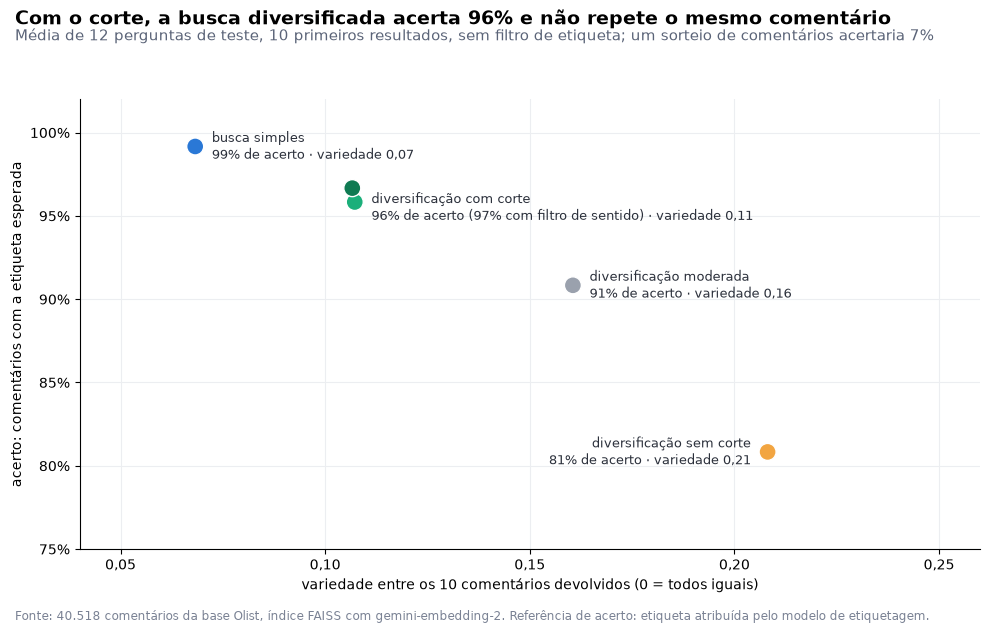

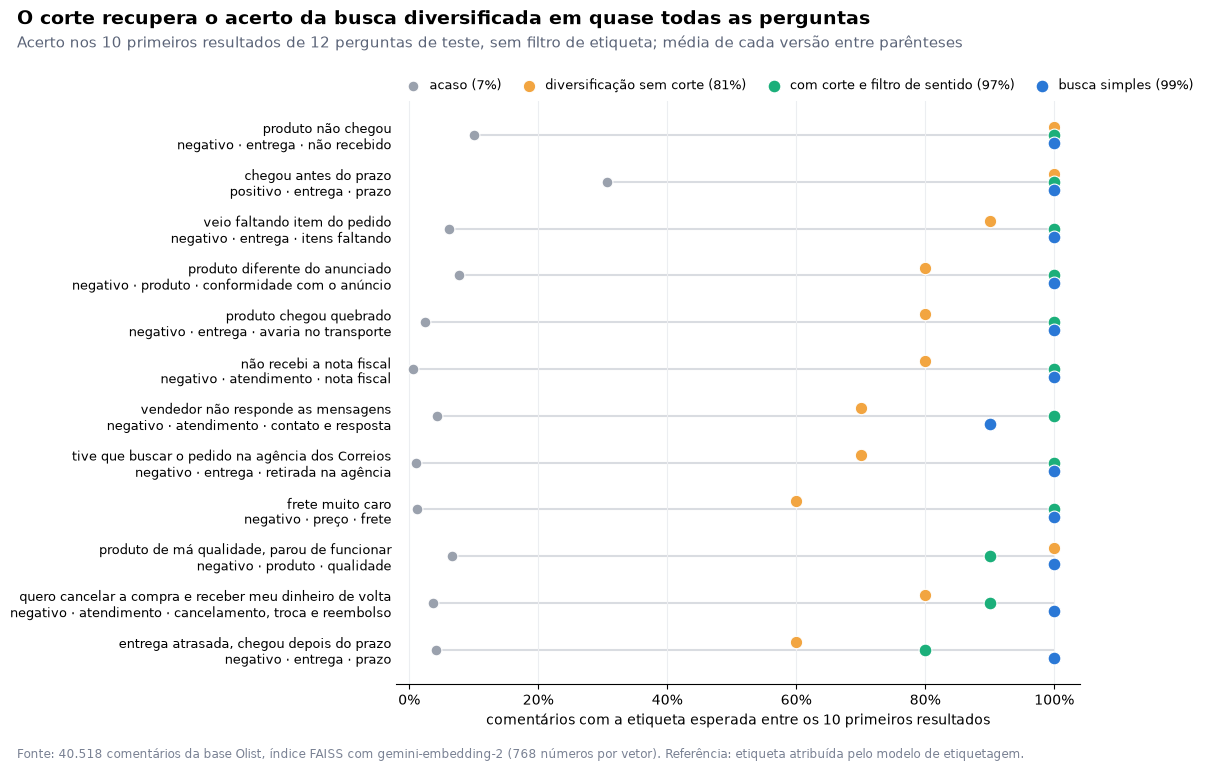

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

TESTE_BUSCA = [
    ("produto não chegou", "negativo · entrega · não recebido"),
    ("entrega atrasada, chegou depois do prazo", "negativo · entrega · prazo"),
    ("veio faltando item do pedido", "negativo · entrega · itens faltando"),
    ("produto chegou quebrado", "negativo · entrega · avaria no transporte"),
    ("tive que buscar o pedido na agência dos Correios", "negativo · entrega · retirada na agência"),
    ("produto diferente do anunciado", "negativo · produto · conformidade com o anúncio"),
    ("produto de má qualidade, parou de funcionar", "negativo · produto · qualidade"),
    ("vendedor não responde as mensagens", "negativo · atendimento · contato e resposta"),
    ("quero cancelar a compra e receber meu dinheiro de volta", "negativo · atendimento · cancelamento, troca e reembolso"),
    ("não recebi a nota fiscal", "negativo · atendimento · nota fiscal"),
    ("frete muito caro", "negativo · preço · frete"),
    ("chegou antes do prazo", "positivo · entrega · prazo"),
]
VERSOES = {
    "busca simples": lambda p, s: buscar(p, k=10, diversificar=False),
    "diversificação sem corte": lambda p, s: buscar(p, k=10, ajuste="com etiqueta"),
    "diversificação moderada": lambda p, s: buscar(p, k=10, ajuste="moderado"),
    "diversificação com corte": lambda p, s: buscar(p, k=10),
    "com corte e filtro de sentido": lambda p, s: buscar(p, k=10, filtros={"sentido": s}),
}
PASTA_RELATORIOS = RAIZ / "reports" / "busca"
PASTA_FIGURAS = RAIZ / "images" / "busca"
PASTA_RELATORIOS.mkdir(parents=True, exist_ok=True)
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)


def variedade(posicoes):
    v = loja.index.reconstruct_batch(np.asarray(posicoes, dtype="int64"))
    s = v @ v.T
    return 1 - (s.sum() - len(v)) / (len(v) * (len(v) - 1))


linhas = []
for pergunta, esperada in TESTE_BUSCA:
    acaso = documentos["etiquetas"].apply(lambda e: esperada in e).mean()
    linhas.append({"pergunta": pergunta, "etiqueta esperada": esperada, "versão": "acaso", "acerto": acaso, "variedade": np.nan})
    for versao, executar in VERSOES.items():
        achados = executar(pergunta, esperada.split(" · ")[0])
        linhas.append({"pergunta": pergunta, "etiqueta esperada": esperada, "versão": versao,
                       "acerto": achados["etiquetas"].str.contains(esperada, regex=False).mean(),
                       "variedade": variedade(achados["posicao"])})
teste_busca = pd.DataFrame(linhas)
teste_busca.round(3).to_csv(PASTA_RELATORIOS / "teste_busca.csv", index=False)

resumo = teste_busca.groupby("versão", sort=False)[["acerto", "variedade"]].mean()
display(resumo.style.format({"acerto": "{:.0%}", "variedade": "{:.2f}"}, na_rep="-"))
acerto = teste_busca.pivot(index=["pergunta", "etiqueta esperada"], columns="versão", values="acerto")[list(resumo.index)]
display(acerto.style.format("{:.0%}"))

# figura 1: a troca entre acerto e variedade, média de cada versão
cores = {"busca simples": "#2a78d6", "diversificação sem corte": "#f2a541", "diversificação moderada": "#9aa1ad",
         "diversificação com corte": "#1baf7a", "com corte e filtro de sentido": "#0f7a52"}
fig, ax = plt.subplots(figsize=(10, 6.2))
pontos = resumo.drop(index="acaso")
ax.scatter(pontos["variedade"], pontos["acerto"], s=150, color=[cores[v] for v in pontos.index], zorder=3,
           edgecolor="white", linewidth=1)


def rotulo(versao, texto, deslocamento, alinhamento="left"):
    linha = resumo.loc[versao]
    ax.annotate(texto, (linha["variedade"], linha["acerto"]), xytext=deslocamento, textcoords="offset points",
                fontsize=9.5, ha=alinhamento, va="center", color="#2b303b")


def virgula(valor):
    return f"{valor:.2f}".replace(".", ",")


rotulo("busca simples", f"busca simples\n{resumo.loc['busca simples', 'acerto']:.0%} de acerto · variedade "
       f"{virgula(resumo.loc['busca simples', 'variedade'])}", (12, 0))
rotulo("diversificação com corte", f"diversificação com corte\n{resumo.loc['diversificação com corte', 'acerto']:.0%} de acerto "
       f"({resumo.loc['com corte e filtro de sentido', 'acerto']:.0%} com filtro de sentido) · variedade "
       f"{virgula(resumo.loc['diversificação com corte', 'variedade'])}", (12, -4))
rotulo("diversificação moderada", f"diversificação moderada\n{resumo.loc['diversificação moderada', 'acerto']:.0%} de acerto · "
       f"variedade {virgula(resumo.loc['diversificação moderada', 'variedade'])}", (12, 0))
rotulo("diversificação sem corte", f"diversificação sem corte\n{resumo.loc['diversificação sem corte', 'acerto']:.0%} de acerto · "
       f"variedade {virgula(resumo.loc['diversificação sem corte', 'variedade'])}", (-12, 0), "right")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0.75, 1.02)
ax.set_xlim(0.04, 0.26)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.2f}".replace(".", ","))
ax.grid(color="#eceef1")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("variedade entre os 10 comentários devolvidos (0 = todos iguais)")
ax.set_ylabel("acerto: comentários com a etiqueta esperada")
fig.suptitle(f"Com o corte, a busca diversificada acerta {resumo.loc['diversificação com corte', 'acerto']:.0%} "
             "e não repete o mesmo comentário", x=0.02, y=0.995, ha="left", fontsize=14, fontweight="bold")
fig.text(0.02, 0.945, f"Média de 12 perguntas de teste, 10 primeiros resultados, sem filtro de etiqueta; um sorteio de comentários acertaria {resumo.loc['acaso', 'acerto']:.0%}",
         fontsize=10.5, color="#5b6478")
fig.text(0.02, 0.01, "Fonte: 40.518 comentários da base Olist, índice FAISS com gemini-embedding-2. "
         "Referência de acerto: etiqueta atribuída pelo modelo de etiquetagem.", fontsize=8.5, color="#7a8294")
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
fig.savefig(PASTA_FIGURAS / "acerto_variedade_busca.png", dpi=160, bbox_inches="tight")
plt.show()

# figura 2: acerto por pergunta nas versões principais
series = {"acaso": ("#9aa1ad", 60, 0), "diversificação sem corte": ("#f2a541", 80, 0.17),
          "com corte e filtro de sentido": ("#1baf7a", 85, 0), "busca simples": ("#2a78d6", 85, -0.17)}
ordem = acerto.sort_values(["com corte e filtro de sentido", "diversificação sem corte"])
fig, ax = plt.subplots(figsize=(11, 7.6))
y = np.arange(len(ordem))
ax.hlines(y, ordem[list(series)].min(axis=1), ordem[list(series)].max(axis=1), color="#d9dce1", lw=1.5, zorder=1)
for versao, (cor, tamanho, deslocamento) in series.items():
    ax.scatter(ordem[versao], y + deslocamento, s=tamanho, color=cor, label=f"{versao} ({resumo.loc[versao, 'acerto']:.0%})",
               zorder=3, edgecolor="white", linewidth=0.8)
ax.set_yticks(y, [f"{p}\n{e}" for p, e in ordem.index], fontsize=9)
for rotulo in ax.get_yticklabels():
    rotulo.set_linespacing(1.3)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(-0.02, 1.04)
ax.grid(axis="x", color="#eceef1")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("comentários com a etiqueta esperada entre os 10 primeiros resultados")
ax.legend(loc="lower left", bbox_to_anchor=(-0.01, 0.995), ncol=4, frameon=False, fontsize=9, handletextpad=0.3, columnspacing=1.2)
fig.suptitle(f"O corte recupera o acerto da busca diversificada em quase todas as perguntas",
             x=0.02, y=0.995, ha="left", fontsize=14, fontweight="bold")
fig.text(0.02, 0.945, "Acerto nos 10 primeiros resultados de 12 perguntas de teste, sem filtro de etiqueta; "
         "média de cada versão entre parênteses", fontsize=10.5, color="#5b6478")
fig.text(0.02, 0.01, "Fonte: 40.518 comentários da base Olist, índice FAISS com gemini-embedding-2 (768 números por vetor). "
         "Referência: etiqueta atribuída pelo modelo de etiquetagem.", fontsize=8.5, color="#7a8294")
fig.tight_layout(rect=(0, 0.03, 1, 0.925))
fig.subplots_adjust(top=0.875)
fig.savefig(PASTA_FIGURAS / "teste_busca.png", dpi=160, bbox_inches="tight")
plt.show()

**Leitura.** A busca simples acertou o assunto em 99% dos resultados (119 de 120), contra 7% de um sorteio, mas com variedade de 0,07: devolve quase sempre a mesma frase. A diversificação sem corte tem a maior variedade (0,21) e o menor acerto (81%): para encontrar variedade, escolhe comentários de assuntos vizinhos, como "não chegou" na pergunta sobre atraso. O corte de 0,05 descarta esses candidatos antes da escolha e devolve o acerto a 96% (97% com o filtro de sentido), com variedade de 0,11, acima da busca simples. A diversificação moderada fica entre as duas (91% e 0,16).

As versões formam uma troca: mais acerto, menos variedade. Sem filtro de etiqueta, o projeto prioriza o acerto, porque um comentário fora do assunto apresentado como evidência compromete a resposta. Com filtro de etiqueta, o assunto já está garantido, e a diversificação sem corte acrescenta variedade. A pergunta mais difícil continua sendo a de atraso (80% com corte e filtro de sentido), na fronteira entre atraso e não recebido, a mesma que o manual v2 precisou resolver na etiquetagem.

## 7. Busca nas perguntas do enunciado

Duas perguntas do enunciado pedem variedade de evidência, e não só contagem:

| Pergunta do enunciado | Como a busca entra |
|---|---|
| 4. Quais padrões podem ser identificados nas avaliações de clientes insatisfeitos? | sem etiqueta específica: filtro de sentido negativo e corte de 0,05 |
| 5. Quais avaliações sustentam a conclusão de que existem problemas recorrentes de prazo? | com filtro da etiqueta de atraso: diversificação sem corte |

Na etapa 6, a resposta a essas perguntas combina contagem e busca. Aqui só a busca é testada: os 8 comentários que ela devolveria como evidência. Para a pergunta 5, a busca também roda sem o filtro de etiqueta, para comparar.

In [7]:
colunas = ["similaridade", "nota", "estado", "comentário", "etiquetas"]

pergunta_4 = "padrões nas avaliações de clientes insatisfeitos"
print(f"pergunta 4 | filtros: sentido negativo | ajuste: {ajuste_para({'sentido': 'negativo'})}")
display(buscar(pergunta_4, k=8, filtros={"sentido": "negativo"})[colunas])

pergunta_5 = "avaliações que mostram problemas recorrentes de prazo de entrega"
filtros_5 = {"etiqueta": "negativo · entrega · prazo"}
print(f"pergunta 5 | filtros: {filtros_5} | ajuste: {ajuste_para(filtros_5)}")
display(buscar(pergunta_5, k=8, filtros=filtros_5)[colunas])
print("pergunta 5 | sem filtro de etiqueta | ajuste: sem etiqueta")
display(buscar(pergunta_5, k=8, filtros={"sentido": "negativo"})[colunas])

pergunta 4 | filtros: sentido negativo | ajuste: sem etiqueta


,similaridade,nota,estado,comentário,etiquetas
0,0.777,2,PE,insatisfeito,negativo · geral · sem assunto
1,0.735,1,SP,A loja vende um produto muito caro mas a qualidade é péssima,negativo · preço · preço do produto; negativo · produto · qualidade
2,0.733,1,MA,"Chegou o produto atrasado, faltando outro. Falta chegar os demais. O cliente está zangado.",negativo · entrega · prazo; negativo · entrega · itens faltando; negativo · entrega · não recebido
3,0.752,1,MG,"tenho reclamaçoes quanto ao produto. nao atendeu minhas expectativas, acho mesmo que veio com defeito pois nao funci...",negativo · produto · qualidade
4,0.731,1,AL,Falta de compromisso com o cliente,negativo · atendimento · outro
5,0.733,1,SP,Não gostei do tratamento ao cliente faz pouco caso não esto contento com a loja.,negativo · atendimento · contato e resposta
6,0.741,1,RJ,não fiquei satisfeito com o material do produto,negativo · produto · qualidade
7,0.735,1,CE,Ainda não recebi meu pedido e nem sei porque eu estou muito insastifeito.,negativo · entrega · não recebido


pergunta 5 | filtros: {'etiqueta': 'negativo · entrega · prazo'} | ajuste: com etiqueta


,similaridade,nota,estado,comentário,etiquetas
0,0.862,1,DF,Não atende o prazo de entrega,negativo · entrega · prazo
1,0.782,1,RJ,"Todas as etapas de entrega tiveram um problema, o objeto chegou com atraso em tudo e até agora consta que não chegou...",negativo · entrega · prazo; negativo · entrega · não recebido
2,0.779,1,RN,Veio primeiro uma forma no prazo. As outras estavam datadas pra 60 dias... Com muita reclamação mandaram as outras d...,negativo · entrega · prazo
3,0.788,1,SP,encomenda 20 dias atrasada para ser entregue,negativo · entrega · prazo
4,0.778,3,SC,"O PRODUTO CHEGOU NO PRAZO, PORÉM, NO ÚLTIMO DIA DO PRAZO. DEMOROU MUITO, PODERIA SER MAIS RÁPIDO.",positivo · entrega · prazo; negativo · entrega · prazo
5,0.792,1,BA,como posso avaliar o produto? só posso avaliar o tempo de entrega que por sinal está atrasado.,negativo · entrega · prazo
6,0.784,1,RJ,"Achei o prazo para entrega muito longo (40 dias) e a loja ainda atrasou um dia. Pela primeira vez, comprei um produt...",negativo · entrega · prazo
7,0.777,3,MG,"DEMORA NO PRAZO DA ENTREGA PRA UM FRETE TÃO CARO, VÁRIAS LOJAS E VÁRIAS TAXAS DE TRANSPORTE",negativo · entrega · prazo; negativo · preço · frete


pergunta 5 | sem filtro de etiqueta | ajuste: sem etiqueta


,similaridade,nota,estado,comentário,etiquetas
0,0.862,1,DF,Não atende o prazo de entrega,negativo · entrega · prazo
1,0.817,1,SP,DEMORA DIMAIS NA ENTREGA PEDIDO AVALIAÇÃO E O PRODUTO AINDA NEM CHEGOU,negativo · entrega · não recebido
2,0.824,4,SP,Produto entregue além do prazo estimado.,negativo · entrega · prazo
3,0.822,2,PR,"Empresa que não entrega o produto no prazo, precisa ser avaliada - são exatamente 30 dias da compra, inclusive com o...",negativo · entrega · não recebido
4,0.812,3,RN,O prazo de entrega é muito longo. Tem lojas que entregam com 8 dias,negativo · entrega · prazo
5,0.820,1,SP,"Prazo de Entrga muito longo , e quando chega a data prevista , não entrega. - PessimoParceiro",negativo · entrega · não recebido
6,0.812,1,RJ,gostaria de saber o por que os pedidos não chegam no prazo,negativo · entrega · prazo
7,0.827,1,PR,nao entregou produto no prazo,negativo · entrega · prazo


**Leitura.** Na pergunta 4, a busca com filtro de sentido e corte devolveu oito queixas de assuntos diferentes: qualidade, preço, atendimento, atraso com itens faltando e produto não recebido, além de uma insatisfação sem assunto. É a variedade esperada numa pergunta sobre padrões; a contagem dos padrões, na etapa 6, vem das etiquetas e das combinações entre elas (D-027).

Na pergunta 5, o filtro da etiqueta de atraso devolveu oito relatos diferentes do problema: encomenda 20 dias atrasada, prazo de 40 dias, entrega no último dia do prazo, atraso combinado com frete caro. Sem o filtro de etiqueta, três dos oito comentários são de produtos que ainda não tinham chegado, a fronteira já vista no teste. O resultado confirma o desenho: para sustentar uma conclusão sobre um problema etiquetado, a busca trabalha dentro do filtro da etiqueta.